# Práctica 3.3 Regresión - Minería de Datos
**Facultad de Ingeniería, UNAM**

**Equipo:** Luis Angel Echevarria Aguilar, Leonardo Alan Lee Roble, Luna Alberto Darwin Leonel

## 1. Definición del Caso de Negocio

### 1.1 Caso de negocio
**Objetivo:** predecir el contenido de alcohol de un vino a partir de sus propiedades químicas y de color.

Medir el grado alcohólico en laboratorio requiere un análisis específico. Si las demás mediciones (acidez, fenoles, color, prolina, etc.) ya se tienen, un modelo que estime el alcohol permite:
- contar con una **estimación rápida** cuando no se dispone de la medición directa;
- **detectar muestras inconsistentes** (un alcohol medido muy distinto del esperado por el modelo merece revisión);
- **entender qué características químicas se asocian más con el grado alcohólico**, que es la parte interpretable de la práctica.

### 1.2 Variable objetivo (dependiente)
`Alcohol` es una variable **continua** (porcentaje de alcohol, con decimales), por lo que el problema es de **regresión** y no de clasificación. Las demás columnas numéricas son las variables independientes (predictoras). `Muestra` es solo un identificador y no se usa como predictora.

### 1.3 Diccionario de variables
| Variable | Qué mide (interpretación química) | Rol |
|---|---|---|
| `Muestra` | Número de renglón / identificador de la muestra | Identificador (se descarta) |
| `Alcohol` | Contenido de alcohol del vino | **Objetivo** |
| `Acido Malico` | Acidez asociada al ácido málico | Predictora |
| `Ceniza` | Residuo mineral total | Predictora |
| `Ceniza Alcalina` | Alcalinidad de la ceniza | Predictora |
| `Magnesio` | Concentración de magnesio | Predictora |
| `Fenoles` | Fenoles totales (compuestos que aportan color, astringencia y aroma) | Predictora |
| `Flavonoides` | Subgrupo de fenoles con propiedades antioxidantes | Predictora |
| `No Flavoniodes Fenosl` | Fenoles que no son flavonoides (el nombre conserva el error de captura del archivo original) | Predictora |
| `Protocianinas` | Proantocianidinas (taninos) | Predictora |
| `Color Intenso` | Intensidad del color del vino | Predictora |
| `Matiz` | Tonalidad del color | Predictora |
| `Concentracion Proteinas` | Concentración relativa de proteínas / compuestos diluidos (medida espectrofotométrica) | Predictora |
| `Prolina` | Aminoácido; su concentración depende de la uva y de la maduración | Predictora |

> Las interpretaciones químicas son descriptivas y sirven para dar contexto; el análisis de las siguientes secciones se basa únicamente en los datos.

In [ ]:
import os
import datetime
try:                                    # silencia el DeprecationWarning de utcnow() en Colab
    import jupyter_client.session as _jc
    _jc.utcnow = lambda: datetime.datetime.now(datetime.timezone.utc)
except Exception:
    pass

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split, RepeatedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# ---- Estilo de gráficas (colores validados: contraste y daltonismo) ----
AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#898781'
COL_MODELO = {'Regresión Lineal': AZUL, 'Árbol de Decisión': NARANJA, 'Bosque Aleatorio': AQUA}
DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#d9443b'])   # azul - gris - rojo
SEC = LinearSegmentedColormap.from_list('sec', ['#eaf1fb', '#2a78d6', '#0d2f5e'])   # un solo tono
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'text.color': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'figure.dpi': 100})
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

### 1.4 Carga del archivo
Se carga `vino_contenido de alcohol.csv`. Si se ejecuta en Google Colab y el archivo no está en la carpeta de trabajo, la celda abre el selector para subirlo. Además se limpian espacios sobrantes en los nombres de columna (el archivo trae `Matiz ` con un espacio al final, lo que provoca errores al llamar la columna por su nombre).

In [ ]:
ARCHIVO = 'vino_contenido de alcohol.csv'
if not os.path.exists(ARCHIVO):
    try:
        from google.colab import files
        print('Sube el archivo', ARCHIVO)
        subido = files.upload()
        ARCHIVO = list(subido.keys())[0]
    except ImportError:
        raise FileNotFoundError(f'No se encontró {ARCHIVO} en la carpeta de trabajo')

df = pd.read_csv(ARCHIVO)
df.columns = df.columns.str.strip()          # 'Matiz ' -> 'Matiz'
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')
display(df.head())

Filas: 178 | Columnas: 14


,Muestra,Alcohol,Acido Malico,Ceniza,Ceniza Alcalina,Magnesio,Fenoles,Flavonoides,No Flavoniodes Fenosl,Protocianinas,Color Intenso,Matiz,Concentracion Proteinas,Prolina
0,1,14.2300,1.7100,2.4300,15.6000,127,2.8000,3.0600,0.2800,2.2900,5.6400,1.0400,3.9200,1065
1,2,13.2400,2.5900,2.8700,21.0000,118,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735
2,3,13.1600,2.3600,2.6700,18.6000,101,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185
3,4,14.1000,2.0200,2.4000,18.8000,103,2.7500,2.9200,0.3200,2.3800,6.2000,1.0700,2.7500,1060
4,5,12.4300,1.5300,2.2900,21.5000,86,2.7400,3.1500,0.3900,1.7700,3.9400,0.6900,2.8400,352


## 2. Calidad de los datos

Antes de modelar se revisan los tipos de dato, los valores nulos, los duplicados y los estadísticos básicos. Un nulo o un duplicado distorsionan los modelos y las métricas. Se espera cero nulos, cero duplicados y variables numéricas; también conviene notar que `Prolina` y `Magnesio` están en cientos y `Matiz` cerca de 1, razón por la que más adelante se estandariza.

In [ ]:
print('Tipos de dato y nulos por columna:')
display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos': df.isna().sum(), 'valores únicos': df.nunique()}))
print(f'Renglones duplicados (sin contar Muestra): {df.drop(columns=["Muestra"]).duplicated().sum()}')
print('\nEstadísticos descriptivos:')
display(df.drop(columns=['Muestra']).describe().T)

Tipos de dato y nulos por columna:


,tipo,nulos,valores únicos
Muestra,int64,0,178
Alcohol,float64,0,126
Acido Malico,float64,0,133
Ceniza,float64,0,79
Ceniza Alcalina,float64,0,63
Magnesio,int64,0,53
Fenoles,float64,0,97
Flavonoides,float64,0,132
No Flavoniodes Fenosl,float64,0,39
Protocianinas,float64,0,101


Renglones duplicados (sin contar Muestra): 0

Estadísticos descriptivos:


,count,mean,std,min,25%,50%,75%,max
Alcohol,178.0000,13.0006,0.8118,11.0300,12.3625,13.0500,13.6775,14.8300
Acido Malico,178.0000,2.3363,1.1171,0.7400,1.6025,1.8650,3.0825,5.8000
Ceniza,178.0000,2.3665,0.2743,1.3600,2.2100,2.3600,2.5575,3.2300
Ceniza Alcalina,178.0000,19.4949,3.3396,10.6000,17.2000,19.5000,21.5000,30.0000
Magnesio,178.0000,99.7416,14.2825,70.0000,88.0000,98.0000,107.0000,162.0000
Fenoles,178.0000,2.2951,0.6259,0.9800,1.7425,2.3550,2.8000,3.8800
Flavonoides,178.0000,2.0293,0.9989,0.3400,1.2050,2.1350,2.8750,5.0800
No Flavoniodes Fenosl,178.0000,0.3619,0.1245,0.1300,0.2700,0.3400,0.4375,0.6600
Protocianinas,178.0000,1.5909,0.5724,0.4100,1.2500,1.5550,1.9500,3.5800
Color Intenso,178.0000,5.0581,2.3183,1.2800,3.2200,4.6900,6.2000,13.0000


## 3. Análisis Exploratorio de Datos (EDA)

El EDA busca responder qué comportamiento tienen las variables y cuáles conviene usar en el modelo. Se avanza de lo general a lo específico:

| Paso | Diagrama | Pregunta |
|---|---|---|
| 3.1 | Histograma y caja de `Alcohol` | ¿Cómo se distribuye el objetivo? |
| 3.2 | Histogramas de predictoras | ¿Qué forma y escala tiene cada variable? |
| 3.3 | Cajas e IQR | ¿Hay valores atípicos? |
| 3.4 | Correlación con `Alcohol` | ¿Cuáles se relacionan más con el objetivo? |
| 3.5 | Mapa de correlación y VIF | ¿Hay variables redundantes? |
| 3.6 | Dispersión | ¿La relación es lineal? |
| 3.7 | Decisión de variables | ¿Cuáles se usan? |

### 3.1 Distribución de la variable objetivo
El histograma y la caja de `Alcohol` permiten ver si el objetivo es simétrico y sin extremos; si lo es, MSE y R² se pueden usar sin transformaciones. La línea punteada es la media: si está cerca de la mediana y no hay puntos fuera de los bigotes, la variable es estable.

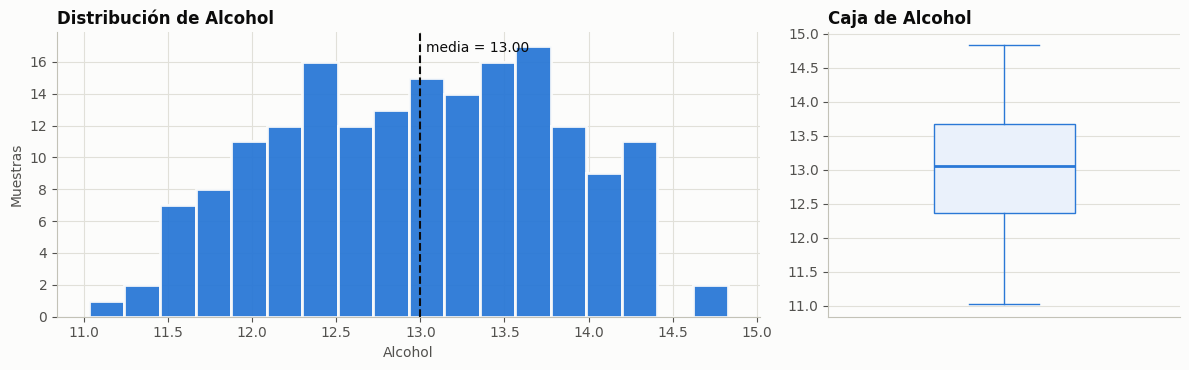

Media 13.001 | Mediana 13.050 | Desv. est. 0.812 | Mín 11.03 | Máx 14.83 | Sesgo -0.051 | Atípicos (IQR): 0


In [ ]:
alc = df['Alcohol']
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [2, 1]})
ax[0].hist(alc, bins=18, color=AZUL, edgecolor='#fcfcfb', linewidth=2, alpha=.95)
ax[0].axvline(alc.mean(), color='#0b0b0b', lw=1.5, ls='--')
ax[0].text(alc.mean() + .03, ax[0].get_ylim()[1] * .93, f'media = {alc.mean():.2f}', fontsize=10)
ax[0].set_title('Distribución de Alcohol'); ax[0].set_xlabel('Alcohol'); ax[0].set_ylabel('Muestras')
ax[1].boxplot(alc, vert=True, widths=.4, patch_artist=True, boxprops=dict(facecolor='#eaf1fb', edgecolor=AZUL),
              medianprops=dict(color=AZUL, lw=2), whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
              flierprops=dict(marker='o', markerfacecolor=NARANJA, markeredgecolor='#fcfcfb', markersize=8))
ax[1].set_title('Caja de Alcohol'); ax[1].set_xticks([]); ax[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

q1, q3 = alc.quantile([.25, .75])
n_out = ((alc < q1 - 1.5 * (q3 - q1)) | (alc > q3 + 1.5 * (q3 - q1))).sum()
print(f'Media {alc.mean():.3f} | Mediana {alc.median():.3f} | Desv. est. {alc.std():.3f} | '
      f'Mín {alc.min():.2f} | Máx {alc.max():.2f} | Sesgo {stats.skew(alc):.3f} | Atípicos (IQR): {n_out}')

### 3.2 Distribución de las variables predictoras
Un histograma por variable independiente, con su sesgo (cerca de 0 es simétrica; más de ±0.5 indica cola marcada). Sirve para detectar escalas muy distintas y distribuciones sesgadas, lo que justifica estandarizar: la regresión lineal depende de la escala y los árboles no.

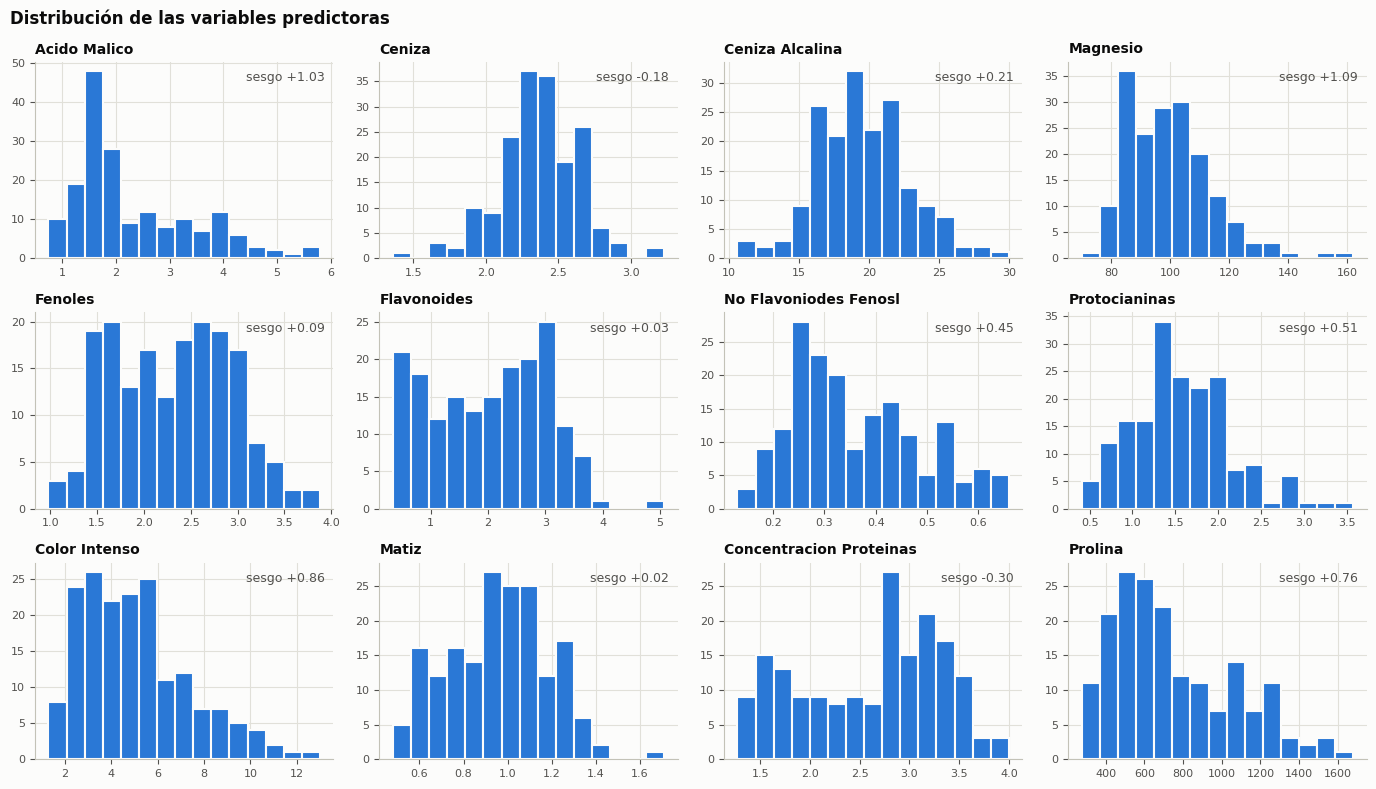

Rango de cada variable (mayor a menor): evidencia de que las escalas son muy distintas


,min,max,rango
Prolina,278.0000,"1,680.0000","1,402.0000"
Magnesio,70.0000,162.0000,92.0000
Ceniza Alcalina,10.6000,30.0000,19.4000
Color Intenso,1.2800,13.0000,11.7200
Acido Malico,0.7400,5.8000,5.0600
Flavonoides,0.3400,5.0800,4.7400
Protocianinas,0.4100,3.5800,3.1700
Fenoles,0.9800,3.8800,2.9000
Concentracion Proteinas,1.2700,4.0000,2.7300
Ceniza,1.3600,3.2300,1.8700


In [ ]:
predictoras = [c for c in df.columns if c not in ('Muestra', 'Alcohol')]
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for a, c in zip(axes.ravel(), predictoras):
    a.hist(df[c], bins=15, color=AZUL, edgecolor='#fcfcfb', linewidth=1.5)
    a.set_title(c, fontsize=10); a.text(.97, .90, f'sesgo {stats.skew(df[c]):+.2f}', transform=a.transAxes,
                                         ha='right', fontsize=9, color='#52514e')
    a.tick_params(labelsize=8)
plt.suptitle('Distribución de las variables predictoras', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

escala = df[predictoras].agg(['min', 'max']).T.assign(rango=lambda t: t['max'] - t['min']).sort_values('rango', ascending=False)
print('Rango de cada variable (mayor a menor): evidencia de que las escalas son muy distintas')
display(escala)

### 3.3 Valores atípicos
Las cajas se dibujan sobre valores estandarizados (z) para comparar variables de escalas distintas. La tabla aplica la regla del IQR (valores a más de 1.5 veces el rango intercuartílico de los cuartiles). Pocos atípicos por variable no justifican eliminar renglones en un conjunto de 178 muestras; pueden ser vinos reales con características particulares.

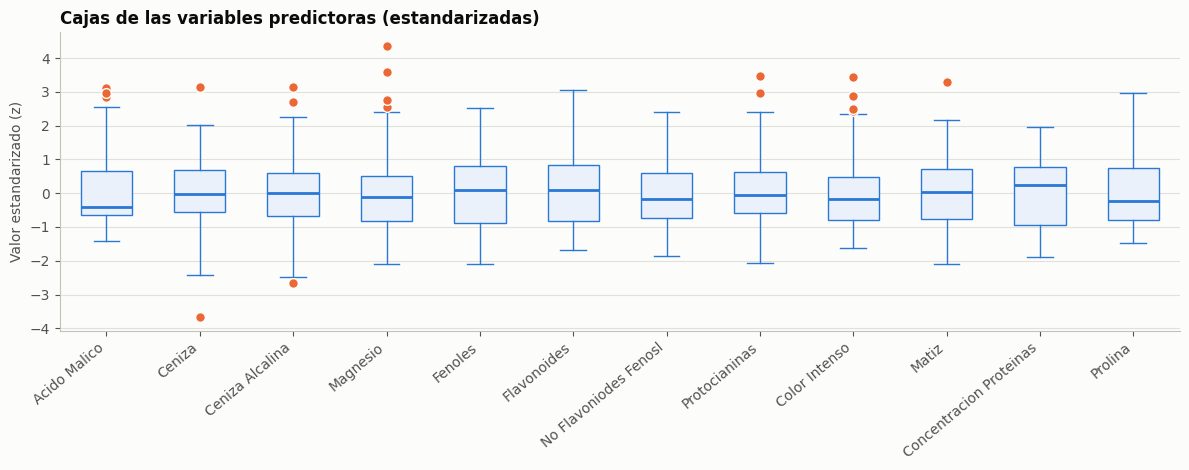

,Variable,Atípicos (IQR),% de muestras
0,Magnesio,4,2.2472
1,Ceniza Alcalina,4,2.2472
2,Color Intenso,4,2.2472
3,Ceniza,3,1.6854
4,Acido Malico,3,1.6854
5,Protocianinas,2,1.1236
6,Matiz,1,0.5618
7,Fenoles,0,0.0000
8,No Flavoniodes Fenosl,0,0.0000
9,Flavonoides,0,0.0000


Máximo de atípicos en una variable: 4 de 178 muestras (2.2%). Total de variables con al menos uno: 7 de 12.


In [ ]:
Z = (df[predictoras] - df[predictoras].mean()) / df[predictoras].std()
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.boxplot([Z[c] for c in predictoras], patch_artist=True, widths=.55,
           boxprops=dict(facecolor='#eaf1fb', edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
           whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
           flierprops=dict(marker='o', markerfacecolor=NARANJA, markeredgecolor='#fcfcfb', markersize=7))
ax.set_xticklabels(predictoras, rotation=40, ha='right'); ax.set_ylabel('Valor estandarizado (z)')
ax.set_title('Cajas de las variables predictoras (estandarizadas)'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

filas = []
for c in predictoras:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    filas.append({'Variable': c, 'Atípicos (IQR)': n, '% de muestras': 100 * n / len(df)})
tab_out = pd.DataFrame(filas).sort_values('Atípicos (IQR)', ascending=False).reset_index(drop=True)
display(tab_out)
print(f'Máximo de atípicos en una variable: {tab_out["Atípicos (IQR)"].max()} de {len(df)} muestras '
      f'({tab_out["% de muestras"].max():.1f}%). Total de variables con al menos uno: {(tab_out["Atípicos (IQR)"] > 0).sum()} de {len(predictoras)}.')

### 3.4 Relación de cada variable con el objetivo
Correlación de cada predictora con `Alcohol`: Pearson mide relación lineal y Spearman relación monótona (si difieren mucho, la relación no es una recta o hay atípicos influyentes). Azul es signo negativo y rojo positivo. Correlación no implica causalidad.

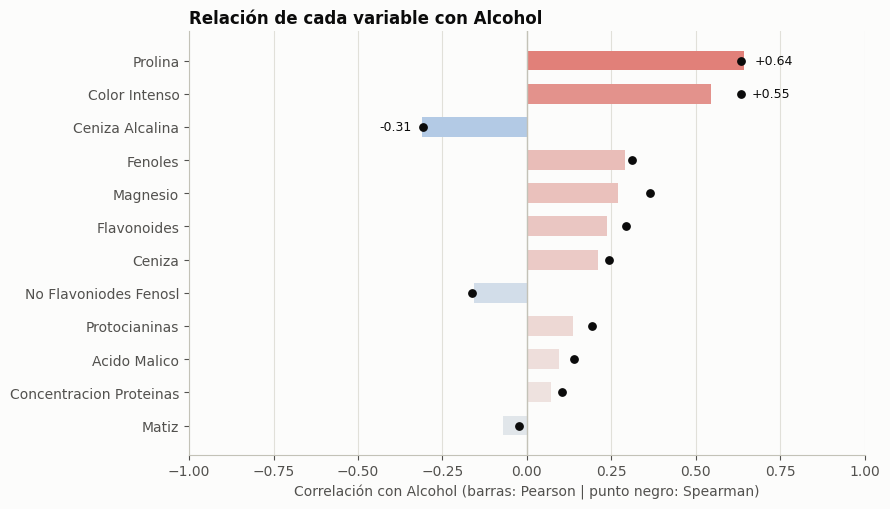

,Pearson,Spearman
Prolina,0.6437,0.6336
Color Intenso,0.5464,0.6354
Ceniza Alcalina,-0.3102,-0.3066
Fenoles,0.2891,0.3109
Magnesio,0.2708,0.3655
Flavonoides,0.2368,0.2947
Ceniza,0.2115,0.2437
No Flavoniodes Fenosl,-0.1559,-0.1622
Protocianinas,0.1367,0.1927
Acido Malico,0.0944,0.1404


In [ ]:
corr_obj = pd.DataFrame({
    'Pearson': [df[c].corr(df['Alcohol']) for c in predictoras],
    'Spearman': [df[c].corr(df['Alcohol'], method='spearman') for c in predictoras],
}, index=predictoras)
corr_obj['|Pearson|'] = corr_obj['Pearson'].abs()
corr_obj = corr_obj.sort_values('|Pearson|', ascending=True)

fig, ax = plt.subplots(figsize=(9, 5.2))
colores = [DIV(0.5 + 0.5 * v) for v in corr_obj['Pearson']]
ax.barh(corr_obj.index, corr_obj['Pearson'], color=colores, height=.6)
ax.scatter(corr_obj['Spearman'], corr_obj.index, color='#0b0b0b', s=28, zorder=3, label='Spearman')
ax.axvline(0, color='#c3c2b7', lw=1)
for y_, v, sp in zip(corr_obj.index[-3:], corr_obj['Pearson'].iloc[-3:], corr_obj['Spearman'].iloc[-3:]):
    xl = max(v, sp) + .03 if v > 0 else min(v, sp) - .03
    ax.text(xl, y_, f'{v:+.2f}', va='center', ha='left' if v > 0 else 'right', fontsize=9)
ax.set_xlim(-1, 1); ax.set_xlabel('Correlación con Alcohol (barras: Pearson | punto negro: Spearman)')
ax.set_title('Relación de cada variable con Alcohol')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
display(corr_obj.sort_values('|Pearson|', ascending=False)[['Pearson', 'Spearman']])

### 3.5 Redundancia entre predictoras: mapa de correlación y VIF
Cuando dos variables miden casi lo mismo (multicolinealidad), la regresión lineal reparte su efecto de forma arbitraria y los coeficientes individuales se vuelven inestables, aunque la predicción siga siendo buena. El mapa muestra la correlación entre pares y el VIF resume cuánto se explica cada variable con las demás (menos de 5 bajo, 5 a 10 moderado, más de 10 severo).

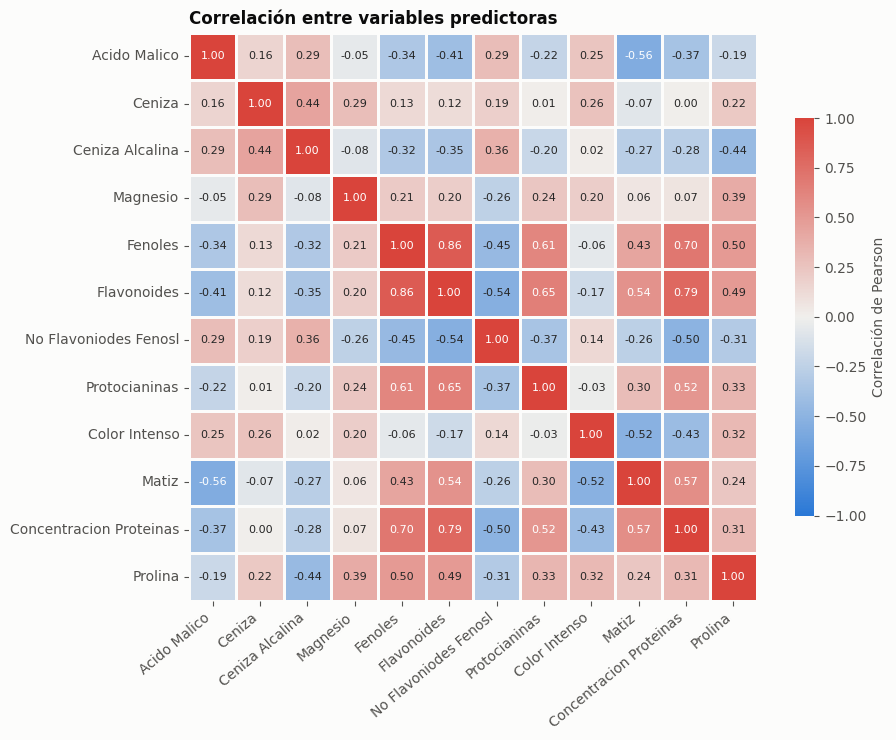

,VIF,Lectura
Flavonoides,7.0290,moderada
Fenoles,4.3306,baja
Concentracion Proteinas,3.7368,baja
Matiz,2.5423,baja
Color Intenso,2.4930,baja
Prolina,2.4418,baja
Ceniza,2.1801,baja
Ceniza Alcalina,2.1793,baja
Protocianinas,1.9472,baja
No Flavoniodes Fenosl,1.7939,baja


Cinco pares de variables más correlacionados:


,,r
Fenoles,Flavonoides,0.8646
Flavonoides,Concentracion Proteinas,0.7872
Fenoles,Concentracion Proteinas,0.6999
Flavonoides,Protocianinas,0.6527
Fenoles,Protocianinas,0.6124


In [ ]:
cm = df[predictoras].corr()
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(cm, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', annot_kws={'size': 8},
            linewidths=2, linecolor='#fcfcfb', square=True, cbar_kws={'shrink': .7, 'label': 'Correlación de Pearson'}, ax=ax)
ax.set_title('Correlación entre variables predictoras'); ax.grid(False)
plt.xticks(rotation=40, ha='right'); plt.tight_layout(); plt.show()

# VIF = diagonal de la inversa de la matriz de correlación
vif = pd.Series(np.diag(np.linalg.inv(cm.values)), index=predictoras, name='VIF').sort_values(ascending=False)
vif_t = vif.to_frame().assign(Lectura=lambda t: np.where(t['VIF'] > 10, 'severa', np.where(t['VIF'] > 5, 'moderada', 'baja')))
display(vif_t)

pares = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool)).stack().rename('r').to_frame()
pares['|r|'] = pares['r'].abs()
print('Cinco pares de variables más correlacionados:')
display(pares.sort_values('|r|', ascending=False).head(5)[['r']])

### 3.6 Forma de la relación: dispersión contra `Alcohol`
Dispersión de `Alcohol` contra las cuatro variables más correlacionadas, con su recta de ajuste. Si la nube fuera claramente curva o en grupos, un modelo de árboles tendría ventaja sobre la regresión lineal; una nube ancha indica que la variable explica solo una parte del alcohol.

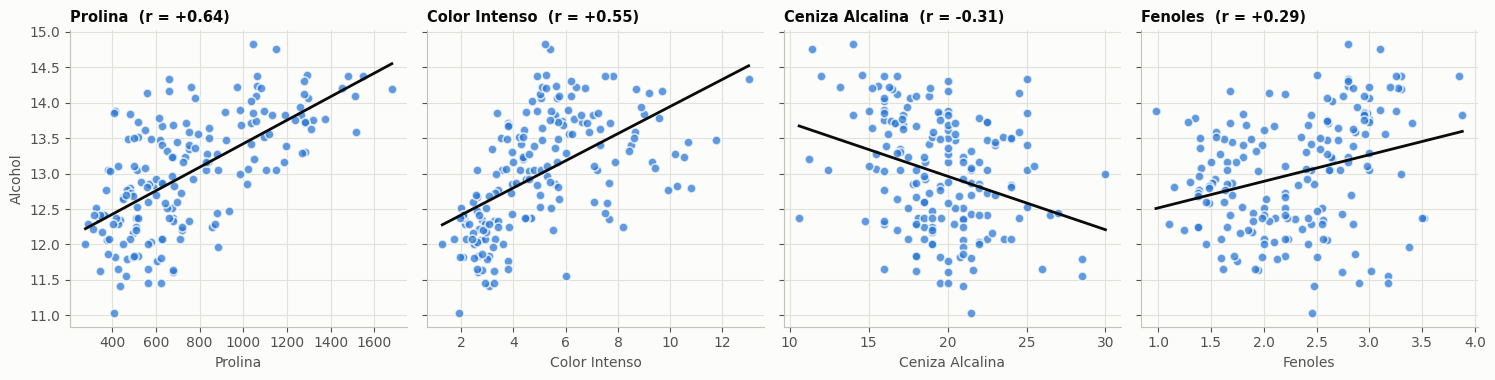

In [ ]:
top4 = corr_obj.sort_values('|Pearson|', ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=True)
for a, c in zip(axes, top4):
    a.scatter(df[c], df['Alcohol'], s=42, color=AZUL, alpha=.75, edgecolor='#fcfcfb', linewidth=1.2)
    m, b = np.polyfit(df[c], df['Alcohol'], 1); xs = np.linspace(df[c].min(), df[c].max(), 50)
    a.plot(xs, m * xs + b, color='#0b0b0b', lw=2)
    a.set_title(f'{c}  (r = {df[c].corr(df["Alcohol"]):+.2f})', fontsize=10.5); a.set_xlabel(c)
axes[0].set_ylabel('Alcohol')
plt.tight_layout(); plt.show()

### 3.7 Decisión de variables: ¿cuáles se utilizan?
Se reúnen los hallazgos en una tabla con un criterio explícito: relación alta con `Alcohol` si |Pearson| ≥ 0.40, media entre 0.20 y 0.40, baja menor a 0.20, y alerta de redundancia si VIF > 5. Después se comprueba con validación cruzada (5 pliegues × 10 repeticiones) si usar menos variables cambia el R², para no eliminar información por intuición.

In [ ]:
tabla_dec = pd.DataFrame({
    '|Pearson| con Alcohol': corr_obj['Pearson'].abs(),
    'Spearman': corr_obj['Spearman'],
    'VIF': vif.reindex(corr_obj.index),
    'Atípicos (IQR)': tab_out.set_index('Variable')['Atípicos (IQR)'].reindex(corr_obj.index),
}).sort_values('|Pearson| con Alcohol', ascending=False)
tabla_dec['Relación'] = pd.cut(tabla_dec['|Pearson| con Alcohol'], [-1, .20, .40, 2], labels=['baja', 'media', 'alta']).astype(str)
tabla_dec['Alerta VIF'] = np.where(tabla_dec['VIF'] > 5, 'sí', 'no')
display(tabla_dec)

# Comparación de subconjuntos con validación cruzada repetida
rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)
orden = list(tabla_dec.index)
subconjuntos = {'Las 12 variables': orden, 'Top 6 por correlación': orden[:6], 'Top 4 por correlación': orden[:4],
                'Top 2 por correlación': orden[:2], 'Sin VIF > 5': [c for c in orden if tabla_dec.loc[c, 'VIF'] <= 5]}
res = []
for nombre, cols in subconjuntos.items():
    fila = {'Subconjunto': nombre, 'Variables': len(cols)}
    for nom_m, mod in [('R² Lineal', LinearRegression()), ('R² Bosque', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]:
        s = cross_validate(Pipeline([('sc', StandardScaler()), ('m', mod)]), df[cols], df['Alcohol'], cv=rkf, scoring='r2', n_jobs=1)
        fila[nom_m] = s['test_score'].mean()
    res.append(fila)
comp_sub = pd.DataFrame(res)
display(comp_sub)
mejor = comp_sub[['R² Lineal', 'R² Bosque']].max()
dif = (mejor - comp_sub.loc[0, ['R² Lineal', 'R² Bosque']])
print(f'Diferencia entre el mejor subconjunto y las 12 variables -> Lineal: {dif["R² Lineal"]:.3f} | Bosque: {dif["R² Bosque"]:.3f} (en R²).')
print('Subconjuntos con 2 variables logran R² de '
      f'{comp_sub.loc[3, "R² Lineal"]:.3f} (lineal) y {comp_sub.loc[3, "R² Bosque"]:.3f} (bosque) frente a '
      f'{comp_sub.loc[0, "R² Lineal"]:.3f} y {comp_sub.loc[0, "R² Bosque"]:.3f} con las 12.')

,|Pearson| con Alcohol,Spearman,VIF,Atípicos (IQR),Relación,Alerta VIF
Prolina,0.6437,0.6336,2.4418,0,alta,no
Color Intenso,0.5464,0.6354,2.4930,4,alta,no
Ceniza Alcalina,0.3102,-0.3066,2.1793,4,media,no
Fenoles,0.2891,0.3109,4.3306,0,media,no
Magnesio,0.2708,0.3655,1.4179,4,media,no
Flavonoides,0.2368,0.2947,7.0290,0,media,sí
Ceniza,0.2115,0.2437,2.1801,3,media,no
No Flavoniodes Fenosl,0.1559,-0.1622,1.7939,0,baja,no
Protocianinas,0.1367,0.1927,1.9472,2,baja,no
Acido Malico,0.0944,0.1404,1.5759,3,baja,no


,Subconjunto,Variables,R² Lineal,R² Bosque
0,Las 12 variables,12,0.4912,0.5264
1,Top 6 por correlación,6,0.5003,0.5286
2,Top 4 por correlación,4,0.5175,0.5380
3,Top 2 por correlación,2,0.5176,0.5129
4,Sin VIF > 5,11,0.5039,0.5309


Diferencia entre el mejor subconjunto y las 12 variables -> Lineal: 0.026 | Bosque: 0.012 (en R²).
Subconjuntos con 2 variables logran R² de 0.518 (lineal) y 0.513 (bosque) frente a 0.491 y 0.526 con las 12.


#### Decisión tomada
- Se **descarta `Muestra`** porque es un identificador (su número de renglón no describe al vino).
- Se **conservan las 12 variables restantes** para los modelos principales. La tabla anterior muestra que reducir el conjunto no mejora de forma importante el R² de validación cruzada, de modo que no hay una ganancia que justifique perder información; además el conjunto es pequeño (178 muestras) y los atípicos son pocos, por lo que no se elimina ningún renglón.
- Las variables con relación alta o media con `Alcohol` y las de VIF alto se **mantienen bajo observación**: la multicolinealidad no afecta a los árboles ni a la capacidad de predicción de la regresión lineal, pero sí obliga a **interpretar con cuidado los coeficientes individuales** (sección 5).
- Se **estandariza** porque las escalas son muy distintas (sección 3.2).

## 4. Preparación de los datos para el modelado

1. Se separa `y = Alcohol` de las predictoras `X` (sin `Muestra`).
2. Se divide en 80% entrenamiento y 20% prueba con `random_state=42` (reproducible); la prueba simula vinos nuevos que el modelo no vio.
3. Se estandariza con `StandardScaler` ajustado solo con entrenamiento, para evitar fuga de datos; así los coeficientes de la regresión lineal quedan comparables.

Se esperan 142 muestras de entrenamiento y 36 de prueba.

In [ ]:
# 1. Limpieza: se elimina el identificador
df_clean = df.drop(columns=['Muestra'])

# 2. Separación de variables (X, y)
X = df_clean.drop(columns=['Alcohol'])
y = df_clean['Alcohol']

# 3. Partición de Datos (Train/Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Normalización / Estandarización (se ajusta solo con entrenamiento)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Datos listos. Muestras de entrenamiento: {X_train.shape[0]}, Muestras de prueba: {X_test.shape[0]}")
print(f"Alcohol medio -> entrenamiento: {y_train.mean():.3f} | prueba: {y_test.mean():.3f}")

# Función auxiliar: métricas en entrenamiento y prueba
def evaluar(modelo, nombre):
    p_tr, p_te = modelo.predict(X_train_scaled), modelo.predict(X_test_scaled)
    return {'Algoritmo de Regresión': nombre,
            'MSE entrenamiento': mean_squared_error(y_train, p_tr), 'R2 entrenamiento': r2_score(y_train, p_tr),
            'MSE prueba': mean_squared_error(y_test, p_te), 'R2 prueba': r2_score(y_test, p_te),
            'RMSE prueba': np.sqrt(mean_squared_error(y_test, p_te))}

def grafica_modelo(imp, col_imp, titulo, color, y_pred, signo=False):
    """Izquierda: participación de las variables. Derecha: valor real vs. predicción."""
    imp = imp.sort_values(col_imp, ascending=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    if signo:   # regresión lineal: se pinta con el signo del coeficiente
        cols = [DIV(0.5 + 0.5 * v / imp[col_imp].abs().max()) for v in imp[col_imp]]
        axes[0].axvline(0, color='#c3c2b7', lw=1)
    else:
        cols = color
    axes[0].barh(imp['Variable'], imp[col_imp], color=cols, height=.62)
    for yy, v in zip(imp['Variable'].iloc[-3:], imp[col_imp].iloc[-3:]):
        axes[0].text(v + imp[col_imp].abs().max() * .015, yy, f'{v:.3f}', va='center', fontsize=9)
    axes[0].set_title(titulo); axes[0].grid(axis='y', visible=False); axes[0].set_xlabel(col_imp)
    axes[1].scatter(y_test, y_pred, s=55, color=color, alpha=.8, edgecolor='#fcfcfb', linewidth=1.5)
    lim = [min(y_test.min(), y_pred.min()) - .1, max(y_test.max(), y_pred.max()) + .1]
    axes[1].plot(lim, lim, color='#0b0b0b', lw=1.5, ls='--')
    axes[1].set_xlabel('Valor Real de Alcohol'); axes[1].set_ylabel('Predicción del Modelo')
    axes[1].set_title('Comportamiento: Real vs Predicción (conjunto de prueba)')
    axes[1].text(.04, .94, 'Línea punteada = predicción perfecta', transform=axes[1].transAxes, fontsize=9, color='#52514e')
    plt.tight_layout(); plt.show()

Datos listos. Muestras de entrenamiento: 142, Muestras de prueba: 36
Alcohol medio -> entrenamiento: 12.986 | prueba: 13.058


## 5. Algoritmo 1: Regresión Lineal Múltiple

Ajusta `Alcohol = b0 + b1·x1 + b2·x2 + ...` minimizando el error cuadrático; es paramétrico e interpretable y sirve como referencia básica. La participación se mide con el **valor absoluto del coeficiente** (variables estandarizadas, por lo que son comparables); el signo indica si la relación es directa o inversa.

El **MSE** es el error cuadrático promedio (menor es mejor), el **RMSE** es su raíz en unidades de alcohol y el **R²** es la proporción de variabilidad explicada (1 es perfecto). Se reportan en entrenamiento y prueba: una caída fuerte en prueba indica sobreajuste. Con variables correlacionadas, un coeficiente individual puede verse reducido porque otra variable comparte su información.


--- 1. REGRESIÓN LINEAL MÚLTIPLE ---
Métricas prueba -> MSE: 0.1670 | RMSE: 0.4087 | R2: 0.6822
Métricas entrenamiento -> MSE: 0.2943 | R2: 0.5717


,Variable,Participación (Absoluta),Coeficiente (con signo),Efecto
0,Color Intenso,0.3574,0.3574,directo (+)
1,Prolina,0.3107,0.3107,directo (+)
2,Ceniza Alcalina,0.1471,-0.1471,inverso (−)
3,Acido Malico,0.1398,0.1398,directo (+)
4,Protocianinas,0.0891,-0.0891,inverso (−)
5,Ceniza,0.0681,0.0681,directo (+)
6,Concentracion Proteinas,0.0663,0.0663,directo (+)
7,Matiz,0.0568,0.0568,directo (+)
8,No Flavoniodes Fenosl,0.0461,-0.0461,inverso (−)
9,Flavonoides,0.0414,0.0414,directo (+)


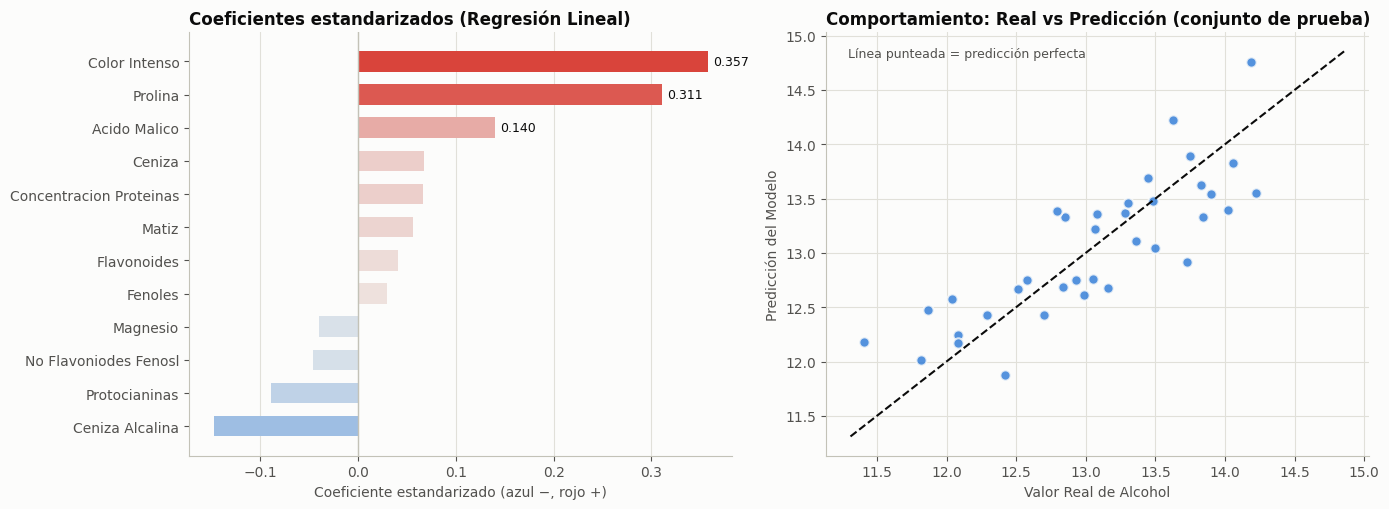

In [ ]:
print("\n--- 1. REGRESIÓN LINEAL MÚLTIPLE ---")
# Entrenamiento
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Predicción
y_pred_lr = lr_model.predict(X_test_scaled)

# Validación de comportamiento (MSE y R2)
mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)
met_lr = evaluar(lr_model, 'Regresión Lineal')
print(f"Métricas prueba -> MSE: {mse_lr:.4f} | RMSE: {np.sqrt(mse_lr):.4f} | R2: {r2_lr:.4f}")
print(f"Métricas entrenamiento -> MSE: {met_lr['MSE entrenamiento']:.4f} | R2: {met_lr['R2 entrenamiento']:.4f}")

# Identificación de variables de mayor participación
importancia_lr = pd.DataFrame({'Variable': X.columns, 'Participación (Absoluta)': abs(lr_model.coef_),
                               'Coeficiente (con signo)': lr_model.coef_})
importancia_lr['Efecto'] = np.where(importancia_lr['Coeficiente (con signo)'] > 0, 'directo (+)', 'inverso (−)')
importancia_lr = importancia_lr.sort_values(by='Participación (Absoluta)', ascending=False).reset_index(drop=True)
display(importancia_lr)

# Gráficas (azul = coeficiente negativo, rojo = positivo)
grafica_modelo(importancia_lr.rename(columns={'Coeficiente (con signo)': 'Coeficiente estandarizado (azul −, rojo +)'}),
               'Coeficiente estandarizado (azul −, rojo +)', 'Coeficientes estandarizados (Regresión Lineal)', AZUL, y_pred_lr, signo=True)

## 6. Algoritmo 2: Regresión de Árbol de Decisión

Divide los datos con preguntas sobre las variables, eligiendo en cada nodo el corte que más reduce el error; la predicción de una hoja es el promedio de sus muestras. No supone relaciones lineales y captura umbrales, lo que lo contrasta con la regresión lineal. La participación se mide con `feature_importances_` (suma 1, siempre positiva, sin dirección del efecto).

Sin límite de profundidad el árbol tiende a memorizar el entrenamiento: se espera R² de entrenamiento cercano a 1 y un R² de prueba mucho menor (sobreajuste). Su importancia también es más inestable, por lo que se verifica con 30 particiones en la sección 8.2.


--- 2. REGRESIÓN DE ÁRBOL DE DECISIÓN ---
Métricas prueba -> MSE: 0.3745 | RMSE: 0.6120 | R2: 0.2873
Métricas entrenamiento -> MSE: 0.0000 | R2: 1.0000
Profundidad del árbol: 16 | Hojas: 138 (para 142 muestras de entrenamiento)


,Variable,Participación,% acumulado
0,Color Intenso,0.5232,52.3220
1,Prolina,0.1428,66.6037
2,Fenoles,0.0816,74.7606
3,No Flavoniodes Fenosl,0.0618,80.9431
4,Protocianinas,0.0463,85.5715
5,Matiz,0.0402,89.5941
6,Flavonoides,0.0276,92.3531
7,Ceniza,0.0228,94.6319
8,Ceniza Alcalina,0.0204,96.6680
9,Magnesio,0.0180,98.4705


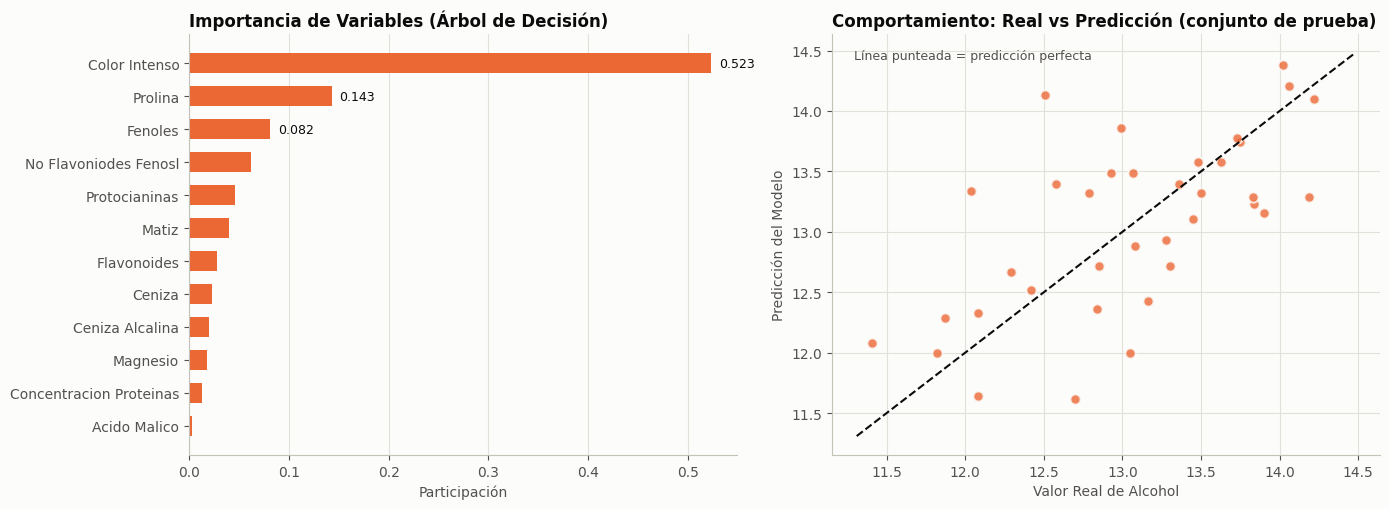

In [ ]:
print("\n--- 2. REGRESIÓN DE ÁRBOL DE DECISIÓN ---")
# Entrenamiento
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train_scaled, y_train)

# Predicción
y_pred_dt = dt_model.predict(X_test_scaled)

# Validación de comportamiento (MSE y R2)
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)
met_dt = evaluar(dt_model, 'Árbol de Decisión')
print(f"Métricas prueba -> MSE: {mse_dt:.4f} | RMSE: {np.sqrt(mse_dt):.4f} | R2: {r2_dt:.4f}")
print(f"Métricas entrenamiento -> MSE: {met_dt['MSE entrenamiento']:.4f} | R2: {met_dt['R2 entrenamiento']:.4f}")
print(f"Profundidad del árbol: {dt_model.get_depth()} | Hojas: {dt_model.get_n_leaves()} (para {len(X_train)} muestras de entrenamiento)")

# Identificación de variables de mayor participación
importancia_dt = pd.DataFrame({'Variable': X.columns, 'Participación': dt_model.feature_importances_})
importancia_dt = importancia_dt.sort_values(by='Participación', ascending=False).reset_index(drop=True)
importancia_dt['% acumulado'] = importancia_dt['Participación'].cumsum() * 100
display(importancia_dt)

# Gráficas
grafica_modelo(importancia_dt, 'Participación', 'Importancia de Variables (Árbol de Decisión)', NARANJA, y_pred_dt)

## 7. Algoritmo 3: Regresión de Bosque Aleatorio (Random Forest)

Ensamble de 100 árboles entrenados con muestras aleatorias de datos y variables; la predicción es el promedio, lo que reduce la varianza del árbol individual. La participación es `feature_importances_` promediada sobre el bosque (suma 1, sin signo). Con solo 36 muestras de prueba, diferencias pequeñas entre modelos no son concluyentes, por lo que la sección 9 usa validación cruzada.


--- 3. REGRESIÓN DE BOSQUE ALEATORIO ---
Métricas prueba -> MSE: 0.1273 | RMSE: 0.3569 | R2: 0.7577
Métricas entrenamiento -> MSE: 0.0450 | R2: 0.9346


,Variable,Participación,% acumulado
0,Color Intenso,0.4415,44.1544
1,Prolina,0.1994,64.0989
2,Fenoles,0.0631,70.4072
3,Ceniza,0.0492,75.3299
4,Protocianinas,0.0443,79.7629
5,Matiz,0.0359,83.3527
6,Acido Malico,0.0329,86.6404
7,Ceniza Alcalina,0.0310,89.7391
8,Concentracion Proteinas,0.0282,92.5614
9,Flavonoides,0.0276,95.3191


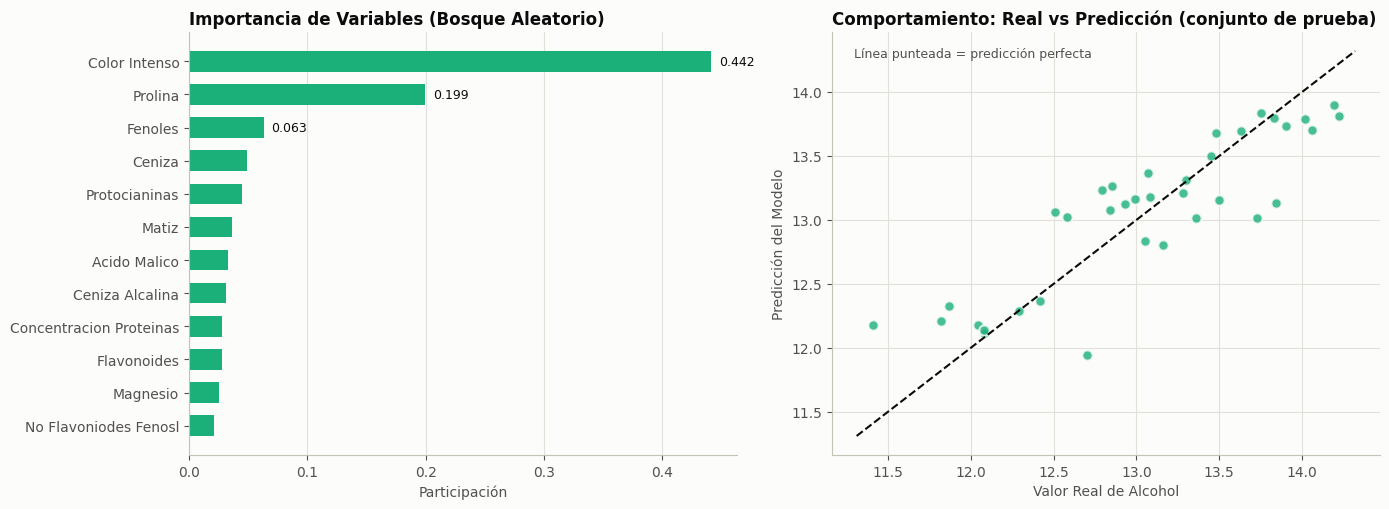

In [ ]:
print("\n--- 3. REGRESIÓN DE BOSQUE ALEATORIO ---")
# Entrenamiento
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Predicción
y_pred_rf = rf_model.predict(X_test_scaled)

# Validación de comportamiento (MSE y R2)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
met_rf = evaluar(rf_model, 'Bosque Aleatorio')
print(f"Métricas prueba -> MSE: {mse_rf:.4f} | RMSE: {np.sqrt(mse_rf):.4f} | R2: {r2_rf:.4f}")
print(f"Métricas entrenamiento -> MSE: {met_rf['MSE entrenamiento']:.4f} | R2: {met_rf['R2 entrenamiento']:.4f}")

# Identificación de variables de mayor participación
importancia_rf = pd.DataFrame({'Variable': X.columns, 'Participación': rf_model.feature_importances_})
importancia_rf = importancia_rf.sort_values(by='Participación', ascending=False).reset_index(drop=True)
importancia_rf['% acumulado'] = importancia_rf['Participación'].cumsum() * 100
display(importancia_rf)

# Gráficas
grafica_modelo(importancia_rf, 'Participación', 'Importancia de Variables (Bosque Aleatorio)', AQUA, y_pred_rf)

## 8. Variables de mayor participación: comparación entre algoritmos

### 8.1 Importancia normalizada
Cada algoritmo mide la participación en una escala distinta, así que cada columna se normaliza para sumar 100%. Una variable oscura en las tres columnas es importante sin importar el algoritmo; si lo es solo en una, depende del método. La tabla da los valores y el promedio de las tres.

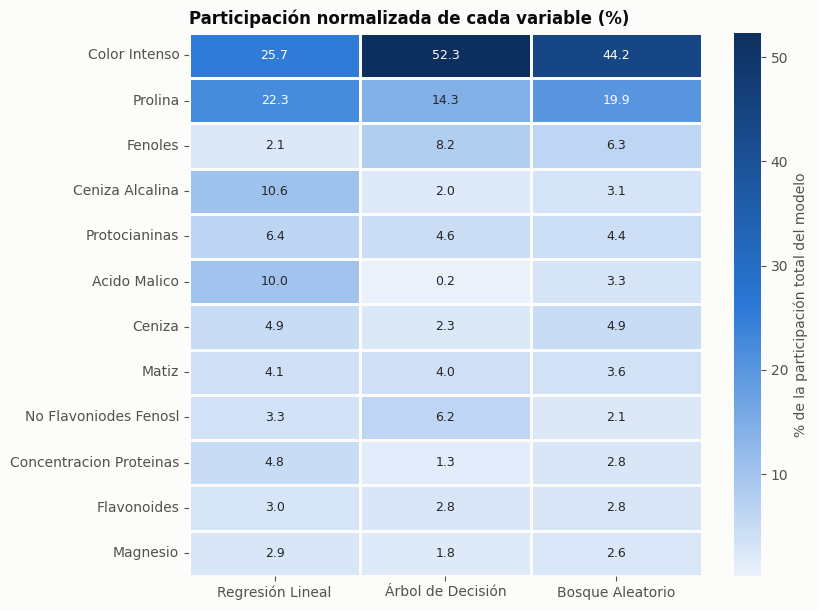

,Regresión Lineal,Árbol de Decisión,Bosque Aleatorio,Promedio
Variable,,,,
Color Intenso,25.7000,52.3000,44.2000,40.7000
Prolina,22.3000,14.3000,19.9000,18.8000
Fenoles,2.1000,8.2000,6.3000,5.5000
Ceniza Alcalina,10.6000,2.0000,3.1000,5.2000
Protocianinas,6.4000,4.6000,4.4000,5.2000
Acido Malico,10.0000,0.2000,3.3000,4.5000
Ceniza,4.9000,2.3000,4.9000,4.0000
Matiz,4.1000,4.0000,3.6000,3.9000
No Flavoniodes Fenosl,3.3000,6.2000,2.1000,3.9000


Dos variables con mayor participación por modelo:
  Regresión Lineal : ['Color Intenso', 'Prolina']
  Árbol de Decisión: ['Color Intenso', 'Prolina']
  Bosque Aleatorio : ['Color Intenso', 'Prolina']
Coinciden en las tres: ['Color Intenso', 'Prolina']


In [ ]:
norm = pd.DataFrame({
    'Regresión Lineal': importancia_lr.set_index('Variable')['Participación (Absoluta)'],
    'Árbol de Decisión': importancia_dt.set_index('Variable')['Participación'],
    'Bosque Aleatorio': importancia_rf.set_index('Variable')['Participación']})
norm = norm / norm.sum() * 100
norm['Promedio'] = norm.mean(axis=1)
norm = norm.sort_values('Promedio', ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 6.2))
sns.heatmap(norm.drop(columns='Promedio'), cmap=SEC, annot=True, fmt='.1f', annot_kws={'size': 9},
            linewidths=2, linecolor='#fcfcfb', cbar_kws={'label': '% de la participación total del modelo'}, ax=ax)
ax.set_title('Participación normalizada de cada variable (%)'); ax.set_ylabel(''); ax.grid(False)
plt.tight_layout(); plt.show()
display(norm.round(1))
top2_lr, top2_dt, top2_rf = [set(imp['Variable'].head(2)) for imp in (importancia_lr, importancia_dt, importancia_rf)]
print('Dos variables con mayor participación por modelo:')
print(f'  Regresión Lineal : {importancia_lr["Variable"].head(2).tolist()}')
print(f'  Árbol de Decisión: {importancia_dt["Variable"].head(2).tolist()}')
print(f'  Bosque Aleatorio : {importancia_rf["Variable"].head(2).tolist()}')
print(f'Coinciden en las tres: {sorted(top2_lr & top2_dt & top2_rf)}')

### 8.2 ¿Es estable el ranking? Prueba con 30 particiones distintas
Se repite el entrenamiento con 30 semillas de partición y se cuenta cuántas veces cada variable queda entre las dos más importantes de cada modelo. Con 178 muestras el ranking podría cambiar según qué vinos caigan en entrenamiento; si una variable aparece casi siempre, el hallazgo es confiable.

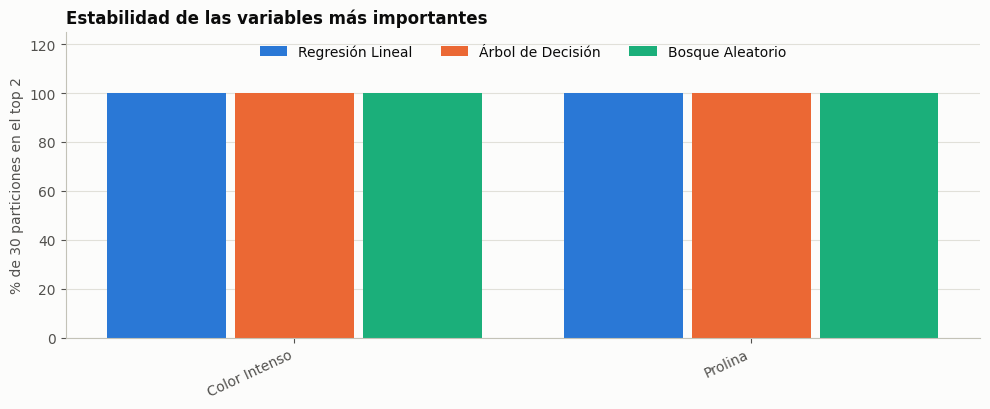

,Regresión Lineal,Árbol de Decisión,Bosque Aleatorio
Color Intenso,100.0000,100.0000,100.0000
Prolina,100.0000,100.0000,100.0000


Regresión Lineal: Color Intenso (100%), Prolina (100%)
Árbol de Decisión: Color Intenso (100%), Prolina (100%)
Bosque Aleatorio: Color Intenso (100%), Prolina (100%)


In [ ]:
conteo = {m: pd.Series(0, index=X.columns, dtype=float) for m in ['Regresión Lineal', 'Árbol de Decisión', 'Bosque Aleatorio']}
SEMILLAS = range(30)
for s in SEMILLAS:
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=s)
    sc = StandardScaler().fit(Xa); Xa_s = sc.transform(Xa)
    imps = {'Regresión Lineal': np.abs(LinearRegression().fit(Xa_s, ya).coef_),
            'Árbol de Decisión': DecisionTreeRegressor(random_state=42).fit(Xa_s, ya).feature_importances_,
            'Bosque Aleatorio': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(Xa_s, ya).feature_importances_}
    for m, v in imps.items():
        conteo[m][pd.Series(v, index=X.columns).nlargest(2).index] += 1
estab = pd.DataFrame(conteo) / len(SEMILLAS) * 100
estab = estab.loc[estab.max(axis=1) > 0].sort_values('Regresión Lineal', ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
anc = .26; pos = np.arange(len(estab))
for k, (m, col) in enumerate(COL_MODELO.items()):
    ax.bar(pos + (k - 1) * (anc + .02), estab[m], width=anc, color=col, label=m)
ax.set_xticks(pos); ax.set_xticklabels(estab.index, rotation=25, ha='right'); ax.set_ylim(0, 125)
ax.set_ylabel('% de 30 particiones en el top 2'); ax.set_title('Estabilidad de las variables más importantes')
ax.legend(frameon=False, ncol=3, loc='upper center'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
display(estab.round(0))
for m in estab.columns:
    mejor2 = estab[m].nlargest(2)
    print(f'{m}: {", ".join(f"{v} ({p:.0f}%)" for v, p in mejor2.items())}')

## 9. Validación del comportamiento: MSE y R²

### 9.1 Partición única entrenamiento / prueba
Se juntan las métricas de los tres modelos. Un buen modelo tiene MSE bajo y R² alto en prueba; la brecha entre el R² de entrenamiento y el de prueba mide el sobreajuste. Como la prueba tiene solo 36 muestras, una sola partición puede favorecer a un modelo por azar y se complementa en 9.2.


=== RESUMEN DE COMPORTAMIENTO DE LOS 3 ALGORITMOS (una sola partición) ===


,Algoritmo de Regresión,MSE entrenamiento,R2 entrenamiento,MSE prueba,R2 prueba,RMSE prueba,Brecha R2 (entren. - prueba)
0,Bosque Aleatorio,0.0450,0.9346,0.1273,0.7577,0.3569,0.1769
1,Regresión Lineal,0.2943,0.5717,0.1670,0.6822,0.4087,-0.1105
2,Árbol de Decisión,0.0000,1.0000,0.3745,0.2873,0.6120,0.7127


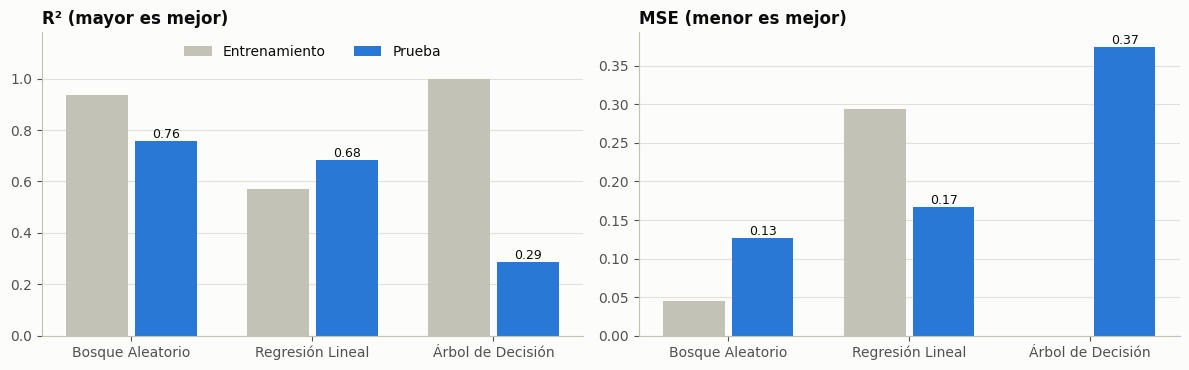

In [ ]:
print("\n=== RESUMEN DE COMPORTAMIENTO DE LOS 3 ALGORITMOS (una sola partición) ===")
tabla_comparativa = pd.DataFrame([met_lr, met_dt, met_rf])
tabla_comparativa['Brecha R2 (entren. - prueba)'] = tabla_comparativa['R2 entrenamiento'] - tabla_comparativa['R2 prueba']
# Ordenado por el mejor desempeño (R2 de prueba más alto)
tabla_comparativa = tabla_comparativa.sort_values(by='R2 prueba', ascending=False).reset_index(drop=True)
display(tabla_comparativa)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
nombres = tabla_comparativa['Algoritmo de Regresión'].tolist(); pos = np.arange(3)
for a, (c_tr, c_te, tit) in zip(ax, [('R2 entrenamiento', 'R2 prueba', 'R² (mayor es mejor)'),
                                      ('MSE entrenamiento', 'MSE prueba', 'MSE (menor es mejor)')]):
    a.bar(pos - .19, tabla_comparativa[c_tr], width=.34, color='#c3c2b7', label='Entrenamiento')
    a.bar(pos + .19, tabla_comparativa[c_te], width=.34, color=AZUL, label='Prueba')
    a.set_xticks(pos); a.set_xticklabels(nombres); a.set_title(tit); a.grid(axis='x', visible=False)
    for p_, v in zip(pos + .19, tabla_comparativa[c_te]):
        a.text(p_, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
ax[0].set_ylim(0, 1.18); ax[0].legend(frameon=False, loc='upper center', ncol=2)
plt.tight_layout(); plt.show()

### 9.2 Validación cruzada repetida (5 pliegues × 10 repeticiones)
Cada modelo se entrena y evalúa 50 veces con particiones distintas, con el escalador dentro de un `Pipeline` para ajustarlo solo con los datos de entrenamiento de cada pliegue. Se reporta media ± desviación estándar: si la diferencia entre dos modelos es menor que esa variabilidad, no se puede afirmar que uno sea mejor. El MSE viene de `neg_mean_squared_error` y aquí se convierte a positivo.

,Algoritmo de Regresión,MSE (media),MSE (desv.),R2 (media),R2 (desv.),R2 entrenamiento (media)
0,Bosque Aleatorio,0.2994,0.0709,0.5257,0.1414,0.9363
1,Regresión Lineal,0.3239,0.0676,0.4912,0.1106,0.6019
2,Árbol de Decisión,0.5439,0.1290,0.1372,0.2316,1.0000


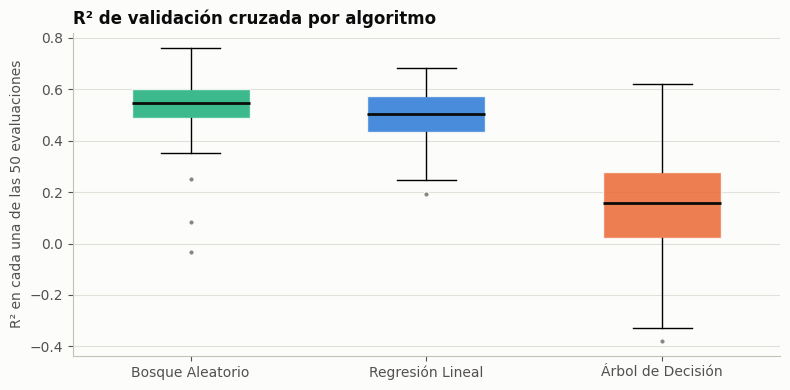

Diferencia de R² entre Bosque Aleatorio y Regresión Lineal (por pliegue): media +0.0345, Bosque Aleatorio mejor en 68% de los 50 pliegues.


In [ ]:
modelos_cv = {'Regresión Lineal': LinearRegression(), 'Árbol de Decisión': DecisionTreeRegressor(random_state=42),
              'Bosque Aleatorio': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)}
rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)
filas, cv_raw = [], {}
for nom, mod in modelos_cv.items():
    s = cross_validate(Pipeline([('sc', StandardScaler()), ('m', mod)]), X, y, cv=rkf,
                       scoring=('neg_mean_squared_error', 'r2'), return_train_score=True, n_jobs=1)
    cv_raw[nom] = s
    filas.append({'Algoritmo de Regresión': nom,
                  'MSE (media)': -s['test_neg_mean_squared_error'].mean(), 'MSE (desv.)': s['test_neg_mean_squared_error'].std(),
                  'R2 (media)': s['test_r2'].mean(), 'R2 (desv.)': s['test_r2'].std(),
                  'R2 entrenamiento (media)': s['train_r2'].mean()})
tabla_cv = pd.DataFrame(filas).sort_values('R2 (media)', ascending=False).reset_index(drop=True)
display(tabla_cv)

fig, ax = plt.subplots(figsize=(8, 4))
datos = [cv_raw[n]['test_r2'] for n in tabla_cv['Algoritmo de Regresión']]
bp = ax.boxplot(datos, patch_artist=True, widths=.5, medianprops=dict(color='#0b0b0b', lw=2),
                flierprops=dict(marker='o', markersize=4, markerfacecolor=GRIS, markeredgecolor='#fcfcfb'))
for patch, n in zip(bp['boxes'], tabla_cv['Algoritmo de Regresión']):
    patch.set_facecolor(COL_MODELO[n]); patch.set_alpha(.85); patch.set_edgecolor('#fcfcfb')
ax.set_xticklabels(tabla_cv['Algoritmo de Regresión']); ax.set_ylabel('R² en cada una de las 50 evaluaciones')
ax.set_title('R² de validación cruzada por algoritmo'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

# Diferencia pareada entre los dos mejores (mismos pliegues)
a_, b_ = tabla_cv['Algoritmo de Regresión'][:2]
d = cv_raw[a_]['test_r2'] - cv_raw[b_]['test_r2']
print(f'Diferencia de R² entre {a_} y {b_} (por pliegue): media {d.mean():+.4f}, '
      f'{a_} mejor en {(d > 0).mean() * 100:.0f}% de los {len(d)} pliegues.')

## 10. Conclusión y Comparación de Modelos

Las conclusiones se generan a partir de los resultados calculados en este cuaderno, así que el texto se mantiene coherente con las tablas si cambian los datos o las semillas. Después se añaden la interpretación del equipo y las limitaciones.

In [ ]:
mejor_cv = tabla_cv.iloc[0]; peor_cv = tabla_cv.iloc[-1]
mejor_te = tabla_comparativa.iloc[0]
v_comunes = sorted(top2_lr & top2_dt & top2_rf)
dt_row = tabla_comparativa.set_index('Algoritmo de Regresión').loc['Árbol de Decisión']
dt_cv = tabla_cv.set_index('Algoritmo de Regresión').loc['Árbol de Decisión']
lr_cv = tabla_cv.set_index('Algoritmo de Regresión').loc['Regresión Lineal']

print("Conclusión Final:\n")
print("1. Variables de mayor participación")
if len(v_comunes) == 2:
    print(f"   Las dos variables con mayor participación en los tres algoritmos son {v_comunes[0]} y {v_comunes[1]}.")
else:
    print(f"   Las dos primeras de cada modelo no coinciden por completo; en común: {v_comunes if v_comunes else 'ninguna'}.")
for m in norm.columns[:3]:
    t = norm[m].nlargest(2)
    print(f"   - {m}: " + " y ".join(f"{v} ({p:.1f}%)" for v, p in t.items()))
print(f"   Promedio de las tres: " + ", ".join(f"{v} ({p:.1f}%)" for v, p in norm['Promedio'].nlargest(3).items()) + ".")

print(f"   Estabilidad: en 30 particiones distintas, cada una de estas dos variables quedó entre las dos primeras en al menos {estab.loc[v_comunes].min().min():.0f}% de las particiones, en los tres modelos." if len(v_comunes) == 2 else "")

print("\n2. Desempeño")
print(f"   En la partición de prueba, el mejor R2 es de {mejor_te['Algoritmo de Regresión']} ({mejor_te['R2 prueba']:.3f}).")
print(f"   En validación cruzada (50 evaluaciones): mejor = {mejor_cv['Algoritmo de Regresión']} "
      f"(R2 {mejor_cv['R2 (media)']:.3f} ± {mejor_cv['R2 (desv.)']:.3f}, MSE {mejor_cv['MSE (media)']:.3f}); "
      f"peor = {peor_cv['Algoritmo de Regresión']} (R2 {peor_cv['R2 (media)']:.3f}).")
dif_top = tabla_cv['R2 (media)'].iloc[0] - tabla_cv['R2 (media)'].iloc[1]
print(f"   Diferencia entre los dos mejores: {dif_top:.3f} de R2, "
      + ("menor que la desviación estándar entre particiones: no es una diferencia concluyente."
         if dif_top < tabla_cv['R2 (desv.)'].iloc[:2].max() else "mayor que la desviación entre particiones."))

print("\n3. Sobreajuste del Árbol de Decisión")
print(f"   R2 de entrenamiento {dt_row['R2 entrenamiento']:.3f} contra {dt_row['R2 prueba']:.3f} en prueba "
      f"y {dt_cv['R2 (media)']:.3f} en validación cruzada: "
      + ("el árbol memoriza el entrenamiento y generaliza peor que los demás." if dt_cv['R2 (media)'] < lr_cv['R2 (media)']
         else "hay brecha entre entrenamiento y prueba, aunque en validación cruzada no queda por debajo de la regresión lineal."))

Conclusión Final:

1. Variables de mayor participación
   Las dos variables con mayor participación en los tres algoritmos son Color Intenso y Prolina.
   - Regresión Lineal: Color Intenso (25.7%) y Prolina (22.3%)
   - Árbol de Decisión: Color Intenso (52.3%) y Prolina (14.3%)
   - Bosque Aleatorio: Color Intenso (44.2%) y Prolina (19.9%)
   Promedio de las tres: Color Intenso (40.7%), Prolina (18.8%), Fenoles (5.5%).
   Estabilidad: en 30 particiones distintas, cada una de estas dos variables quedó entre las dos primeras en al menos 100% de las particiones, en los tres modelos.

2. Desempeño
   En la partición de prueba, el mejor R2 es de Bosque Aleatorio (0.758).
   En validación cruzada (50 evaluaciones): mejor = Bosque Aleatorio (R2 0.526 ± 0.141, MSE 0.299); peor = Árbol de Decisión (R2 0.137).
   Diferencia entre los dos mejores: 0.034 de R2, menor que la desviación estándar entre particiones: no es una diferencia concluyente.

3. Sobreajuste del Árbol de Decisión
   R2 de entre

### Interpretación y limitaciones
**Lectura de los resultados.**
- La concordancia de variables entre algoritmos con principios distintos (uno lineal, otro de particiones, otro de ensamble) da más confianza que el resultado de un solo modelo. La sección 8.2 indica qué tan estable es esa conclusión.
- Un R² moderado significa que **las características químicas explican solo una parte del alcohol**; el resto depende de factores no incluidos (variedad de uva, año, región, proceso de fermentación). No debe presentarse al modelo como una medición sustituta del laboratorio, sino como una estimación orientativa.
- Los modelos de árboles tienen la ventaja de detectar relaciones no lineales; la regresión lineal, la de ser más simple e interpretable. Cuando ambos rinden parecido, **se prefiere el más simple**.

**Limitaciones.**
- Solo 178 muestras: la partición de prueba (36) es pequeña y sus métricas varían bastante entre particiones.
- La importancia basada en coeficientes se ve afectada por la multicolinealidad (sección 3.5), y la importancia de árboles tiende a favorecer variables con muchos valores distintos.
- La importancia y la correlación describen **asociación, no causalidad**.
- Los modelos de árbol y bosque se usaron con sus hiperparámetros por defecto; ajustar profundidad y número de árboles (por ejemplo, con `GridSearchCV`) podría mejorar al árbol, y es una extensión natural de la práctica.